# 13 — GoalScope qualitative demo (paper-style callouts)

Interactive version of `Overleaf-draft/REF/qualitative_demo.png`: source code on the right, italic-quote read-out callouts on the left joined by leader lines to pink anchor dots.

**Interaction:** click a highlighted (scoped) token to pin its read-out — a numbered callout appears, the token is boxed + dotted, and a curve is drawn. Click again (or the ✕) to unpin. Multiple tokens can be pinned. Hover shows a transient preview.

Renderer: `src/goals/goalscope_viz.py`. Input = the `list[dict]` returned by `apply_goalscope(..., include_noncode=True, show=False)`.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
# resolve to the repo root so relative paths (head_sets/, notebooks/diff/visualizations/) work
# regardless of the notebook's launch cwd
while not os.path.isdir('src') and os.getcwd() != '/':
    os.chdir('..')
sys.path.append('.')
print('cwd:', os.getcwd())
from src.goals.goalscope_viz import goalscope_qualitative_html, show_goalscope_qualitative

cwd: /disk/u/arnab/Codes/Projects/goals


## GoalScope: pick the model + goal heads
Set the knobs below (model, mask λ, threshold, layer band, steer layers). Head selection and the layer × head map need no
GPU, so they can be re-run freely; the model loads in the cell after them. *(Heavy — needs free GPU(s). Set `CUDA`.)*

In [2]:
# ── knobs ────────────────────────────────────────────────────────────────────
# MODEL = 'meta-llama/Llama-3.3-70B-Instruct'     'Qwen/Qwen2.5-Coder-32B-Instruct'
MODEL='Qwen/Qwen2.5-Coder-32B-Instruct'
CUDA  = '4'                                     # free GPU(s); Llama-70B in bf16 needs 2 x 80 GB

LAMBDA       = 20       # mask sparsity λ: Llama 5 | 20 | 50 · Coder 1 | 5 | 20 | 50 | 100
THRESHOLD    = 0.9     # keep heads whose mask value > THRESHOLD
BAND         = None    # (lo, hi): keep layers lo <= L < hi · None = the model's preset
STEER_LAYERS = None    # (a, b): GoalScope injects into layers range(a, b) · None = the model's preset
ALPHA        = 0.1

# Coder preset = the paper's GoalScope config: lam20 · thr 0.9 · band 25-56 -> the 122 goal heads, steer 35-46.
# Llama: masks trained on the contextual-token-filter pivot pool ('_ctx', 2026-10-04); band from
# eval_goalscope.GOAL_BANDS. Its steer range is NOT tuned: (44, 57) is Coder's 35-46 scaled by depth (64 -> 80).
PRESETS = {
    'Qwen2.5-Coder-32B-Instruct': dict(mask_suffix='',     band=(25, 56), steer=(35, 46)),
    'Llama-3.3-70B-Instruct':     dict(mask_suffix='_ctx', band=(18, 45), steer=(44, 57)),
}
slug = MODEL.split('/')[-1]
P = PRESETS[slug]
BAND, STEER_LAYERS = BAND or P['band'], STEER_LAYERS or P['steer']
MASK_PATH = f"results/localization/{slug}/lam{LAMBDA}{P['mask_suffix']}/head_mask.pt"
print(f'{MASK_PATH}  ·  thr {THRESHOLD}  ·  band {BAND}  ·  steer {STEER_LAYERS}  ·  alpha {ALPHA}')

results/localization/Qwen2.5-Coder-32B-Instruct/lam20/head_mask.pt  ·  thr 0.9  ·  band (25, 56)  ·  steer (35, 46)  ·  alpha 0.1


122 heads selected  ·  137 > 0.9 in all layers  ·  178 > 0.5
final val recall @1=0.746  @2=0.884  @3=0.919  @4=0.933  @5=0.937
top layers: L49:12  L46:11  L47:11  L45:9  L51:8  L39:7


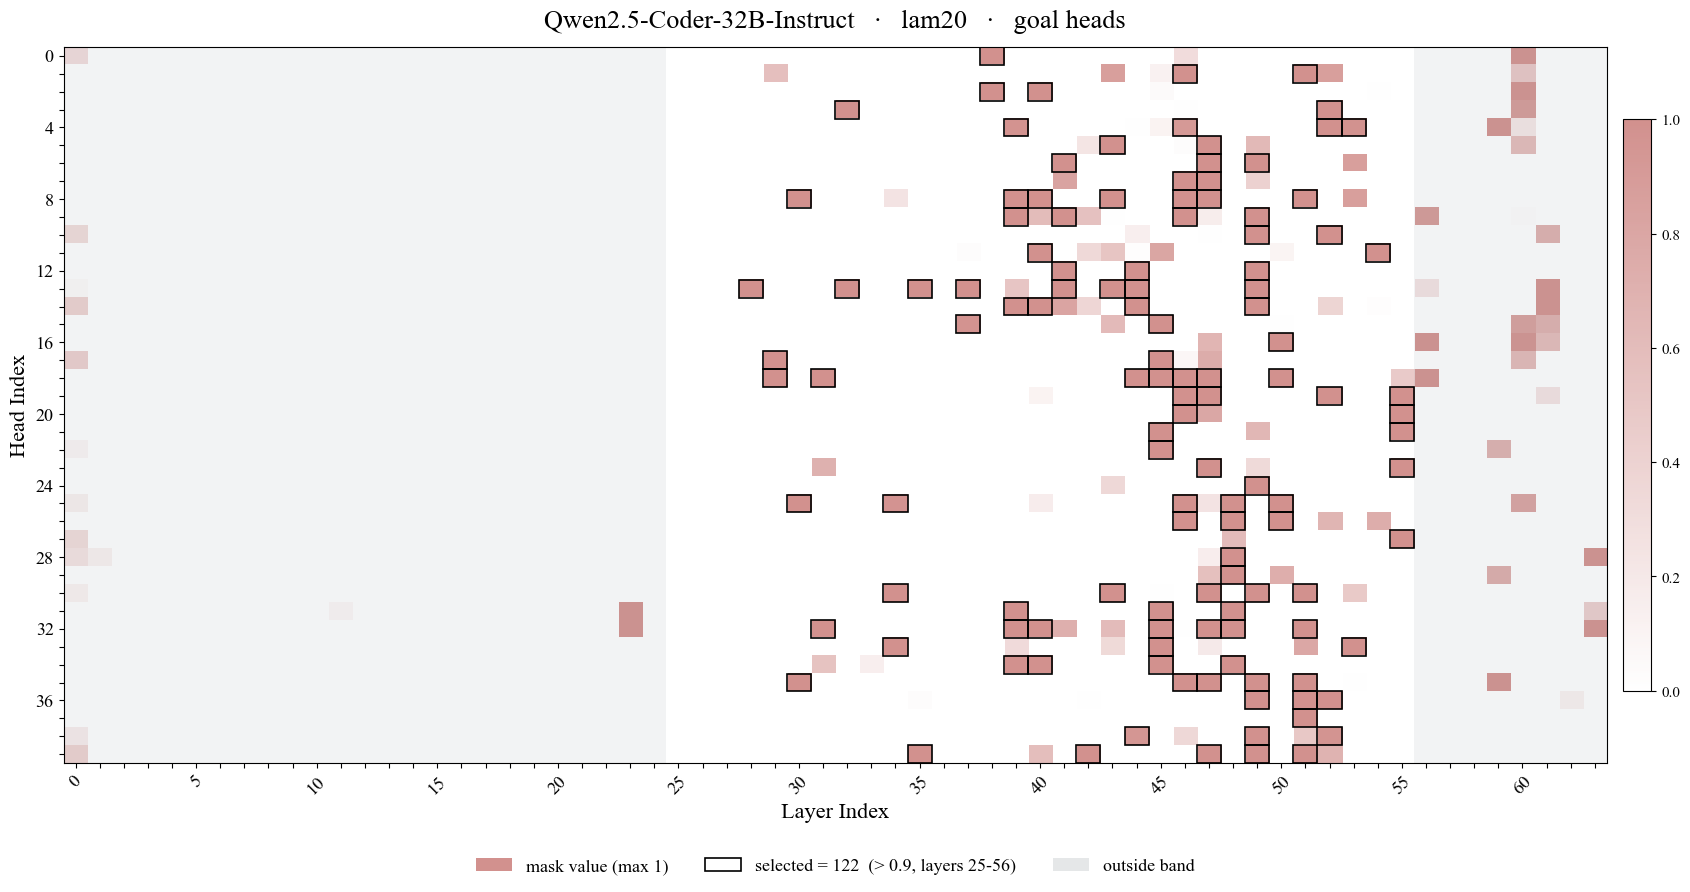

In [3]:
# ── goal heads from the trained mask + layer × head map (no model needed) ──────────
# Same rule as eval_goalscope.load_goal_heads: mask value > THRESHOLD, layer inside BAND.
import numpy as np, torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from collections import Counter

ck = torch.load(MASK_PATH, map_location='cpu', weights_only=False)
M_LAYERS = [int(x) for x in ck['layers']]
MASK = ck['mask_values'].float().numpy()                  # (layers tested, heads)
N_HEADS_M = MASK.shape[1]
in_band = np.array([BAND[0] <= l < BAND[1] for l in M_LAYERS])
SELECTED_HEADS = [(M_LAYERS[i], int(h)) for i, h in np.argwhere((MASK > THRESHOLD) & in_band[:, None])]

hist = ck.get('history', {})
val = hist.get('val_recall') or []
by_layer = Counter(l for l, _ in SELECTED_HEADS)
print(f"{len(SELECTED_HEADS)} heads selected  ·  {int((MASK > THRESHOLD).sum())} > {THRESHOLD} in all layers  ·  "
      f"{int((MASK > 0.5).sum())} > 0.5")
if val:
    print('final val recall ' + '  '.join(f'@{k+1}={v:.3f}' for k, v in enumerate(val[-1])))
print('top layers: ' + '  '.join(f'L{l}:{n}' for l, n in by_layer.most_common(6)))

# layer × head map, styled as notebooks/clock/__head_inspection.ipynb (white = 0 -> terracotta = 1,
# black border = selected, grey wash = outside the band)
plt.rcParams['font.family'] = 'Times New Roman'
SMALL, MEDIUM, BIG = 13, 16, 19
COL, ALPHA_IMG = '#BF625E', 0.7
ticks = lambda n, skip: [str(i) if i % skip == 0 else '' for i in range(n)]

g = np.full((N_HEADS_M, max(M_LAYERS) + 1), np.nan)    # (heads, layers): x = layer, y = head
for i, l in enumerate(M_LAYERS):
    g[:, l] = MASK[i]
n_layer_plot = g.shape[1]
cmap = LinearSegmentedColormap.from_list('goal_seq', ['white', COL], N=256).copy(); cmap.set_bad('#EFEFEF')

fig, ax = plt.subplots(figsize=(17, 9))
im = ax.imshow(np.ma.masked_invalid(g), cmap=cmap, aspect='auto', vmin=0, vmax=1, alpha=ALPHA_IMG,
               interpolation='nearest')
for lo, hi in [(-0.5, BAND[0] - 0.5), (BAND[1] - 0.5, n_layer_plot - 0.5)]:
    if hi > lo:
        ax.axvspan(lo, hi, color='#9AA0A6', alpha=0.12, lw=0)
for l, h in SELECTED_HEADS:
    ax.add_patch(mpatches.Rectangle((l - 0.5, h - 0.5), 1, 1, linewidth=1.2, edgecolor='black', facecolor='none'))
ax.set_xticks(range(n_layer_plot)); ax.set_xticklabels(ticks(n_layer_plot, 5), rotation=45, fontsize=SMALL)
ax.set_yticks(range(N_HEADS_M));   ax.set_yticklabels(ticks(N_HEADS_M, 4), fontsize=SMALL)
ax.set_xlabel('Layer Index', fontsize=MEDIUM); ax.set_ylabel('Head Index', fontsize=MEDIUM)
legend = [mpatches.Patch(facecolor=COL, alpha=ALPHA_IMG, label=f'mask value (max {np.nanmax(MASK):.3g})'),
          mpatches.Patch(facecolor='white', edgecolor='black', linewidth=1.2,
                         label=f'selected = {len(SELECTED_HEADS)}  (> {THRESHOLD}, layers {BAND[0]}-{BAND[1]})'),
          mpatches.Patch(facecolor='#9AA0A6', alpha=0.25, label='outside band')]
ax.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=len(legend),
          fontsize=SMALL, frameon=False)
ax.set_title(f"{slug}   ·   lam{LAMBDA}{P['mask_suffix']}   ·   goal heads", fontsize=BIG, pad=14)
fig.colorbar(im, ax=ax, fraction=0.018, pad=0.01).ax.tick_params(labelsize=SMALL - 2)
plt.tight_layout(); plt.show()

In [4]:
# ── all λ for this model at the current THRESHOLD / BAND — to choose LAMBDA ─────────
import glob, re, os
rows = []
for f in sorted(glob.glob(f"results/localization/{slug}/lam*{P['mask_suffix']}/head_mask.pt")):
    tag = f.split('/')[-2]
    if P['mask_suffix'] == '' and not re.fullmatch(r'lam[0-9.]+', tag):
        continue                                   # Coder: plain lam<λ> dirs only
    c = torch.load(f, map_location='cpu', weights_only=False)
    m = c['mask_values'].float().numpy(); ly = [int(x) for x in c['layers']]
    b = np.array([BAND[0] <= l < BAND[1] for l in ly])
    v = (c.get('history', {}).get('val_recall') or [[float('nan')]])[-1]
    rows.append((tag, int(((m > THRESHOLD) & b[:, None]).sum()), int((m > 0.5).sum()), v[0]))
lam = lambda t: float(re.search(r'lam([0-9.]+)', t).group(1))
print(f"{'mask':12s} {'selected':>9s} {'>0.5 all':>9s} {'val@1':>7s}   (selected = > {THRESHOLD} within {BAND})")
for tag, n, n5, v1 in sorted(rows, key=lambda r: lam(r[0])):
    print(f"{tag:12s} {n:9d} {n5:9d} {v1:7.3f}" + ('   <-' if tag == f"lam{LAMBDA}{P['mask_suffix']}" else ''))

mask          selected  >0.5 all   val@1   (selected = > 0.9 within (25, 56))
lam1               211       406   0.701
lam5               142       184   0.690
lam20              122       178   0.746   <-
lam50               93       111   0.665
lam100              75        81   0.641


In [5]:
heads = SELECTED_HEADS   # from the selection cell; re-run it after changing the knobs
len(heads)

122

In [6]:
import os, torch
os.environ['CUDA_VISIBLE_DEVICES'] = CUDA   # knobs cell
from src.models import ModelandTokenizer
from src.goals.goalscope import apply_goalscope
from scripts.evaluation.eval_goalscope import load_json_heads

mt = ModelandTokenizer(model_key=MODEL, dtype=torch.bfloat16, device_map='auto',
                       attn_implementation='eager')
assert all(0 <= l < mt.n_layer and 0 <= h < mt.model.config.num_attention_heads for l, h in SELECTED_HEADS)
print(f'{len(heads)} goal heads  ·  {MASK_PATH}  ·  thr {THRESHOLD}  ·  band {BAND}')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

122 goal heads  ·  results/localization/Qwen2.5-Coder-32B-Instruct/lam20/head_mask.pt  ·  thr 0.9  ·  band (25, 56)


In [7]:
from src.functional import generate_with_patch
from rich import print as rich_print
from rich.markup import escape

task = "stable marriage"
# task = "merge sort"
# task = "bubble sort"
# task = "quick sort"

msgs = [
    {'role': 'system', 'content': 'You are a helpful assistant proficient in programming. '
        'Always wrap your code inside <code></code> blocks. Just the code, no need to comment or explain.'},
    {'role': 'user', 'content': f'Implement the {task} algorithm in python'},
    {'role': 'assistant', 'content': f'<code>\n def {task.replace("-", "_")}('},
]
prompt = mt.tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=False,
                                             continue_final_message=True)

gen = generate_with_patch(
    mt=mt,
    inputs=prompt,
    n_gen_per_prompt=1,
    do_sample=False,
    remove_prefix=True,
    max_new_tokens=256
)[0]
rich_print(f"[white]{prompt}[/white][sea_green3]{escape(gen)}[/sea_green3]")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


<|im_start|>system
You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just the 
code, no need to comment or explain.<|im_end|>
<|im_start|>user
Implement the stable marriage algorithm in python<|im_end|>
<|im_start|>assistant
<code>
 def stable marriage(people):
    n = len(people) // 2
    men = people[:n]
    women = people[n:]
    men_prefs = {man: women for man in men}
    women_prefs = {woman: men for woman in women}
    engagements = {}
    free_men = set(men)

    while free_men:
        man = free_men.pop()
        for woman in men_prefs[man]:
            if woman not in engagements:
                engagements[woman] = man
                break
            else:
                current_man = engagements[woman]
                if women_prefs[woman].index(man) < women_prefs[woman].index(current_man):
                    engagements[woman] = man
                    free_men.add(current_man)
                    break

    return engagements

# Example usage:
people = ['m1', 'm2', 'w1', 'w2']
men_preferences = {'m1': ['w1', 'w2'], 'm2': ['w2', 'w1']}
women_preferences = {'w1': ['m1', 'm2'], 'w2': ['m1', 'm2']}
people_preferences = {**men_preferences, **women_preferences}

result = stable_marriage(list(people

In [8]:
STEER_LAYERS = (20, 40)

In [9]:
# Verbalize every code token (include_noncode=True keeps the whole prompt; non-code tokens dimmed).
print(f"{len(heads)=}")

res = apply_goalscope(
    prompt + gen,
    mt=mt,
    selected_heads=heads,
    strategy="additive_norm", alpha=0.11,
    # strategy="replace", alpha=2.0,
    steer_layer_range=STEER_LAYERS,
    n_steer_tokens="all",
    max_new_tokens=64,
    include_noncode=True,
    show=False,
)
print(sum(1 for r in res if r.get("scoped")), "scoped tokens")

len(heads)=122


GoalScope[additive_norm]:   0%|          | 0/17 [00:00<?, ?it/s]

264 scoped tokens


In [ ]:
# Inline (interactive) + save a standalone .html for the paper.
import pathlib; pathlib.Path('notebooks/diff/visualizations').mkdir(parents=True, exist_ok=True)
goalscope_qualitative_html(res, title=f'{task} — GoalScope · {slug}',
                           save_path=f'notebooks/diff/visualizations/{task}__{slug}.html')
show_goalscope_qualitative(res, title=f'{task} — GoalScope · {slug}', height=1224)

/disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/IPython/core/display.py:447: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


: 